# What labfigs does without being asked

**Kernel:** `python3`, the default Python (3.10 or newer) with labfigs installed. Choose it before running.

**Shows:** three panels, each a default at work.

- Left: 95% intervals from draws on a log axis, two methods shifted apart by a few points, true values as marks
  (`lf.intervals`, `lf.dodge`, `lf.marks`).
- Middle: the same comparison in one call (`lf.compare`). Case A is four times larger than the rest,
  so `lf.show` warns that one x position sets the y range. The warning under the figure cell is expected.
- Right: a trace whose ticks enclose the data, with a plain `%` in its label (`lf.trace`).

**Graph type:** interval comparison and a trace.

**Writes:** `defaults.svg` next to this notebook.

**To tweak:** change the capitalised settings at the top of the **Figure** cell and re-run that cell.

**To save:** run the one-line cell under a figure. It writes one file for each type in `FORMATS`, set in the
Setup cell: `("svg",)` by default, `("svg", "pdf", "png")` for all three. Nothing is written until that cell runs.

**To run it all:** `jupyter nbconvert --to notebook --execute --inplace defaults.ipynb`, which also saves the figures in this notebook.

In [1]:
import json
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.figure import Figure

import labfigs as lf

lf.use()
FORMATS = ("svg",)

## Data

Synthetic; swap this cell for your own loading.

- `pressure`: the five x positions
- `truth`: true value at each pressure
- `draws`: `{method name: draws}`, each of shape `(draws, len(pressure))`; the names become legend entries
- `wide_first`: scaling that makes the first case much larger than the others
- `cost`: x positions of the trace

In [2]:
rng = np.random.default_rng(0)
pressure = np.array([1e-3, 1.0, 76.0, 300.0, 760.0])
truth = np.array([5.2, 4.1, 3.6, 3.3, 3.1])
draws = {method: truth + rng.normal(0, 0.35, (400, 5)) for method in ("IFT", "Diffusion")}
wide_first = np.array([4, 1, 1, 1, 1])
cost = np.arange(1, 9)

## Figure

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `PANEL_ASPECT`: height of one panel divided by its width
- `QUANTITY`: y label of the two interval panels
- `PRESSURE_LABEL`, `CASE_LABEL`, `CASES`: x label of the left panel, x label and case names of the middle one
- `TRUE_LABEL`: legend entry of the true values
- `TRACE_LABEL`, `TRACE_X_LABEL`, `TRACE_Y_LABEL`: the right panel's legend entry and axis labels
- `TAG`: short text in the corner of the figure

/var/folders/s6/ytw71ql147s95jjfyww9zvbm0000gn/T/ipykernel_64678/2845017572.py:20: UserWarning: this figure: one x position sets the range of '$k(T_h)/k(T_c)$' (checklist 13): a log axis, or that position in its own panel
  lf.show(fig)


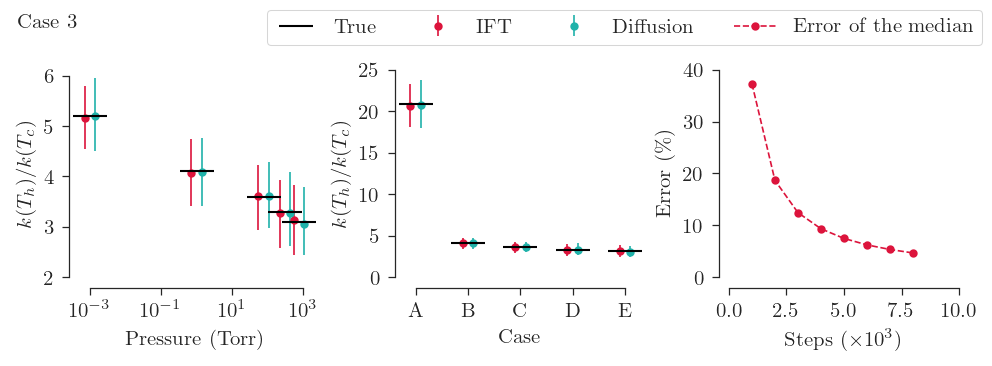

In [3]:
NAME = "defaults"
PANEL_ASPECT = 0.9
QUANTITY = "$k(T_h)/k(T_c)$"
PRESSURE_LABEL, CASE_LABEL, CASES = "Pressure (Torr)", "Case", list("ABCDE")
TRUE_LABEL = "True"
TRACE_LABEL, TRACE_X_LABEL, TRACE_Y_LABEL = "Error of the median", "Steps ($\\times 10^3$)", "Error (%)"
TAG = "Case 3"

fig, (a, b, c) = lf.subplots(1, 3, aspect=PANEL_ASPECT)
for (method, samples), dx in zip(draws.items(), lf.dodge(len(draws))):
    lf.intervals(a, pressure, samples, shift=dx, label=method)
lf.marks(a, pressure, truth, label=TRUE_LABEL)
a.set(xscale="log", xlabel=PRESSURE_LABEL, ylabel=QUANTITY)
lf.compare(b, CASES, {method: samples * wide_first for method, samples in draws.items()}, true=truth * wide_first)
b.set(xlabel=CASE_LABEL, ylabel=QUANTITY)
lf.trace(c, cost, 37.3 / cost, ls="--", label=TRACE_LABEL)
c.set(xlabel=TRACE_X_LABEL, ylabel=TRACE_Y_LABEL)
lf.tag(fig, TAG)
lf.legend_above(fig)
lf.show(fig)

In [4]:
lf.save(fig, NAME, formats=FORMATS)

Saved defaults.svg


## Checks

Fails if one of the library's defaults breaks: the warning above, ticks that enclose the data, the `%` sign,
clipping of shifted intervals, the styles of `lf.truth` and `lf.reference`, how many draws `lf.paths` keeps, the three styles of `lf.posterior`,
the grids of `lf.cases`, the notebook display, the three file types of `lf.save`, and the notebook maker (`lf.notebook`). Nothing to tweak.

In [5]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    lf.check(fig, NAME)
assert [str(w.message).split(":")[1][:14] for w in caught] == [" one x positio"], [str(w.message) for w in caught]
assert c.get_yticks()[0] <= 37.3 / 8 and c.get_yticks()[-1] >= 37.3, c.get_yticks()
assert lf.percent(r"50\%") == lf.percent("50%")
assert a.spines["bottom"].get_bounds()[0] <= 1e-3 and a.spines["bottom"].get_bounds()[1] >= 760, a.spines["bottom"].get_bounds()
assert np.allclose(lf.log_ticks(0.04, 0.7), [0.02, 0.05, 0.1, 0.2, 0.5, 1]) and np.allclose(lf.log_ticks(2e-9, 0.8, 4), [1e-9, 1e-6, 1e-3, 1])
assert [label.get_text() for label in b.get_xticklabels()] == CASES and len(b.lines) == len(a.lines)
assert not lf.overlaps(fig)
c.text(0, 1.02, "Steps", transform=c.transAxes, va="top")
c.text(0, 1.02, "Error", transform=c.transAxes, va="top")
assert lf.overlaps(fig) == [("Steps", "Error")], lf.overlaps(fig)

walks = rng.normal(0, 1, (200, 20)).cumsum(1)
wide, narrow = lf.subplots()[1], lf.subplots(1, 5)[1][0]
level, curve, floor = lf.truth(wide, 1), lf.truth(wide, [0, 1], [0, 1]), lf.reference(wide, 0.5)
assert (level.get_ls(), curve.get_ls(), floor.get_ls(), floor.get_color(), floor.get_label()[:1]) == ("--", "-", "--", lf.REFERENCE, "_")
assert (len(lf.paths(wide, range(20), walks)), len(lf.paths(narrow, range(20), walks))) == (100, 25)
assert len(lf.paths(narrow, range(20), walks, draws=60)) == 60
assert [type(lf.posterior(wide, range(20), walks, style)).__name__ for style in lf.Style] == ["Line2D", "list", "LineCollection"]
assert set(lf.Ramp) == set(lf.RAMPS) and lf.posterior(wide, range(20), walks, lf.Style.BAND, lf.Ramp.HEAT).get_color() == lf.posterior(wide, range(20), walks, lf.Style.DRAWS, lf.Ramp.HEAT)[0].get_color()

crowded = lf.subplots(1, 5)[1][0]
lf.compare(crowded, list("AB"), {str(method): rng.normal(size=(50, 2)) for method in range(4)}, true=[0, 0])
crowded.figure.canvas.draw()
dots = [line for line in crowded.lines if line.get_marker() == "o"]
assert len(dots) == 4 and all(dot.get_clip_box().contains(*xy) for dot in dots for xy in dot.get_transform().transform(dot.get_xydata()))
mark = next(line for line in crowded.lines if line.get_marker() == "_")
half = mark.get_markersize() / 2 * crowded.figure.dpi / 72
assert all(mark.get_clip_box().contains(x + side * half, y) for x, y in mark.get_transform().transform(mark.get_xydata()) for side in (-1, 1))

few, many = lf.cases(list("abc"), ["u", "v"])[1], lf.cases(list("abcde"), ["u", "v"])[1]
assert (few.shape, many.shape) == ((3, 2), (5, 2))
assert (few[0, 0].get_gridspec().ncols, many[0, 0].get_gridspec().ncols) == (3, 2)
assert (few[2, 0].get_title(), many[4, 0].get_ylabel(), many[0, 1].get_title()) == ("c", "e", "v")

assert Figure in get_ipython().display_formatter.formatters["image/svg+xml"].type_printers
plt.switch_backend("agg")
lf.use()
assert plt.isinteractive() and "inline" in plt.get_backend()
folder = Path(tempfile.mkdtemp())
lf.save(fig, folder / "formats", formats=("svg", "pdf", "png"))
assert sorted(file.suffix for file in folder.iterdir()) == [".pdf", ".png", ".svg"]
draft = folder / "draft.py"
draft.write_text("# %% [markdown]\n# # Title\n#\n# Text\n# %%\nx = 1\n")
made = json.loads(lf.notebook(draft, draft).read_text())["cells"]
assert [(cell["cell_type"], "".join(cell["source"])) for cell in made] == [("markdown", "# Title\n\nText"), ("code", "x = 1")]
lf.use(dark=True)
lf.use()
assert plt.rcParams["figure.facecolor"] == "white" and plt.rcParams["text.color"] != lf.NIGHT["ink"]
# keeps the throwaway figures of these checks out of the notebook's output
plt.close("all")

Saved /var/folders/s6/ytw71ql147s95jjfyww9zvbm0000gn/T/tmptoic44qb/formats.svg, /var/folders/s6/ytw71ql147s95jjfyww9zvbm0000gn/T/tmptoic44qb/formats.pdf, /var/folders/s6/ytw71ql147s95jjfyww9zvbm0000gn/T/tmptoic44qb/formats.png
